In [118]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import time

# Parameters
lambda_m = 6e6
lambda_bar_m = 2e6
B = 10e6
p_max_l = 1000000.0
p_max_o = 1000000.0
kappa_m = 1e-28
L0 = 1000
g0 = 1e-4
alpha = 2.0
sigma2 = 1e-9
epsilon = 1e-5
d = 10

In [119]:
# Simulation range
M_values = list(range(2, 40))
solve_times = []
total_energies = []

for M in M_values:
    distances = np.array([(m+1)*d for m in range(M)])
    h_m = g0 * ((distances)**(-alpha/2))

    p_l = cp.Variable(M, pos=True)
    p_o = cp.Variable(M, pos=True)
    gamma = cp.Variable(M, pos=True)

    objective = cp.Minimize(cp.sum(p_l + p_o))
    constraints = []

    for m in range(M):
        interference = sigma2 + cp.sum([p_o[i] * h_m[i]**2 for i in range(m+1, M)])
        constraints += [
            (interference / (p_o[m] * h_m[m]**2)) * gamma[m] <= 1,
            gamma[m] >= max(2**(lambda_bar_m / B) - 1, epsilon),
            p_l[m] >= kappa_m * (L0 * (lambda_m - lambda_bar_m))**3,
            p_l[m] <= p_max_l,
            p_o[m] <= p_max_o
        ]

    problem = cp.Problem(objective, constraints)
    try:
        start = time.time()
        problem.solve(gp=True)
        solve_times.append(time.time() - start)
        total_energies.append(objective.value)
    except:
        solve_times.append(None)
        total_energies.append(None)

In [120]:
distances

array([ 10,  20,  30,  40,  50,  60,  70,  80,  90, 100, 110, 120, 130,
       140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260,
       270, 280, 290, 300, 310, 320, 330, 340, 350, 360, 370, 380, 390])

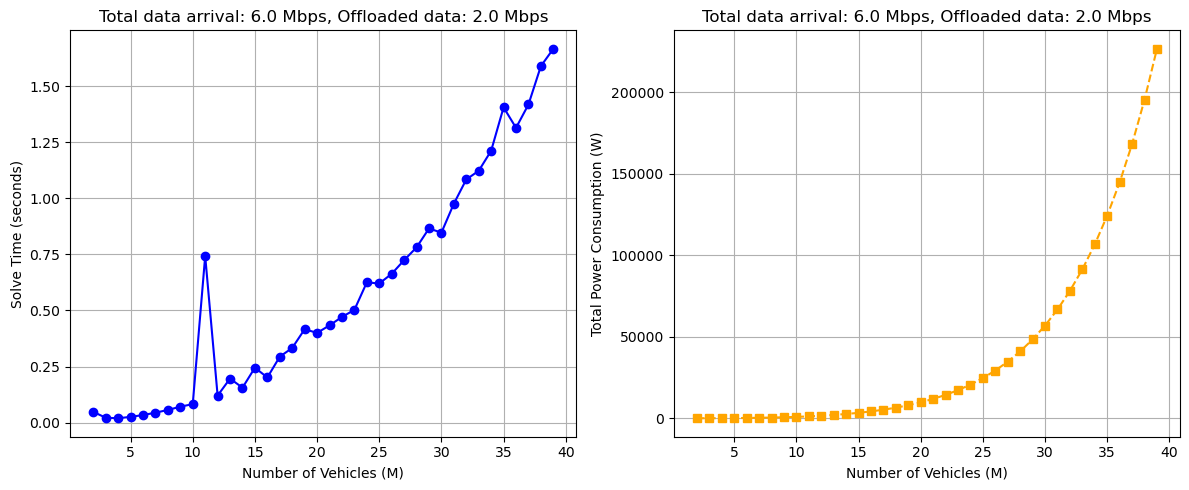

In [121]:
# Graphs
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Time
axs[0].plot(M_values, solve_times, marker='o', linestyle='-', color='blue')
axs[0].set_title(f"Total data arrival: {lambda_m/1000000:.1f} Mbps, Offloaded data: {lambda_bar_m/1000000:.1f} Mbps")
axs[0].set_xlabel("Number of Vehicles (M)")
axs[0].set_ylabel("Solve Time (seconds)")
axs[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axs[0].grid(True)

# Power
axs[1].plot(M_values, total_energies, marker='s', linestyle='--', color='orange')
axs[1].set_title(f"Total data arrival: {lambda_m/1000000:.1f} Mbps, Offloaded data: {lambda_bar_m/1000000:.1f} Mbps")
axs[1].set_xlabel("Number of Vehicles (M)")
axs[1].set_ylabel("Total Power Consumption (W)")
axs[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
axs[1].grid(True)

plt.tight_layout()
plt.show()